In [2]:
import numpy as np
import matplotlib.pyplot as plt

import tidy3d as td
import tidy3d.web as web

In [3]:
lda_min = 1.50
lda_cen = 1.55
lda_max = 1.60

f_min = td.C_0 / lda_max
f_cen = td.C_0 / lda_cen
freq_0 = f_cen
f_max = td.C_0 / lda_min

fwidth = f_max - f_min
lda_list = np.array([1.50, 1.53, 1.55, 1.57, 1.60])
freq_list = td.C_0 / lda_list

inf_eff = 1e5

In [4]:
from tidy3d.plugins.dispersion import AdvancedFastFitterParam, FastDispersionFitter

fit_from_file = False
if fit_from_file:
    #========FITTER========
    f_name_si = 'Pierce.csv'
    fitter_si = FastDispersionFitter.from_file(f_name_si, skiprows=1, delimiter=",")

    advanced_param = AdvancedFastFitterParam(weights=(1, 1), num_iters=40)
    #restrict wavelengths to a smaller bandwidth
    fitter_si = fitter_si.copy(update={"wvl_range": (0.6, 2.066)})
    medium_si_pierce, rms_error = fitter_si.fit(max_num_poles=1, tolerance_rms=2e-2)
    fitter_si.plot(medium_si_pierce)
    plt.show()
    print(medium_si_pierce)
    fname = "misc/medium_si_pierce.json"
    medium_si_pierce.to_file(fname)
else:
    #fname = "misc/medium_si_pierce.json"
    #medium_si_pierce = td.PoleResidue.from_file(fname)
    medium_si_pierce = td.PoleResidue(
        eps_inf=1.0, 
        poles=((np.complex128(-19770699816.093872-4810569113088505j), np.complex128(207324523074.23474+2.5223014349983428e+16j)),), 
        frequency_range=None)

In [5]:
#Malitson 1965: n 0.21–6.7 µm
fit_from_file = False
if fit_from_file:
    #========FITTER========
    f_name_siO2 = 'Malitson.csv'
    fitter_siO2 = FastDispersionFitter.from_file(f_name_siO2, skiprows=1, delimiter=",")

    advanced_param = AdvancedFastFitterParam(weights=(1, 1))
    fitter_siO2 = fitter_siO2.copy(update={"wvl_range": (0.4, 2.2)})
    medium_siO2_malitson, rms_error = fitter_siO2.fit(max_num_poles=1, advanced_param=advanced_param, tolerance_rms=2e-2)
    fitter_siO2.plot(medium_siO2_malitson)
    plt.show()
    print(medium_siO2_malitson)
    fname = "misc/medium_siO2_malitson.json"
    medium_siO2_malitson.to_file(fname)
else:
    #fname = "misc/medium_siO2_malitson.json"
    #medium_siO2_malitson = td.PoleResidue.from_file(fname)
    medium_siO2_malitson = td.PoleResidue(eps_inf=1.0, 
        poles=((np.complex128(-23348480.79859546-1.6968022427402726e+16j), np.complex128(25281492.027727+9186445214622816j)),), 
        frequency_range=None)

In [6]:
#the substrate structure
substrate = td.Structure(geometry=td.Box.from_bounds(rmin=(-inf_eff,-inf_eff,-inf_eff), rmax=(inf_eff,inf_eff,0)), medium=medium_siO2_malitson)
#the nano-pillar
def make_unit_cell(h,D):
    '''
    Construct a nano-pillar structure for the given height and diameter.
    Args:
        h (float): Height of the nano-pillar.
        D (float): Diameter of the nano-pillar.
    Returns:
        td.Structure: The nano-pillar structure.
    '''
    pillar_geo = td.Cylinder(center=(0,0,h/2),radius=D/2, length=h)
    pillar = td.Structure(geometry=pillar_geo, medium=medium_si_pierce)
    return pillar

In [7]:
#all dimensions in [um]
min_P = 0.6
max_P = 0.8
min_h = 0.6
max_h = 0.9
min_D = 0.12
max_D = 0.53

Lz = max_h + 2 * lda_max #simulation domain height
min_steps_per_wvl = 40

In [8]:
#=========SOURCE=========
source_bandwidth = 0.35
source_time = td.GaussianPulse(freq0=freq_0, fwidth=fwidth * source_bandwidth)
#note from the manual:
#The PlaneWave source is normalized to inject 1 W of total power, regardless of the source plane size.
plane_wave = td.PlaneWave(
    source_time=source_time,
    size=(td.inf,td.inf,0),
    center=(0,0,-lda_max+max_h/2),
    direction='+',
    name='planewave',
)

In [9]:
#=======MONITORS AND BOUNDARIES=======
#diffraction monitor to compute unit-cell transmittance
monitor_t = td.DiffractionMonitor(
    center=[0,0,max_h/2 + lda_max],
    size=[td.inf,td.inf,0],
    freqs=freq_list,
    name='transmission_monitor',
    normal_dir='+',
)

boundary_spec = td.BoundarySpec(
    x=td.Boundary.periodic(),
    y=td.Boundary.periodic(),
    z=td.Boundary(minus=td.PML(), plus=td.PML()),
)

In [10]:
run_time = 700 / freq_0
def make_unit_cell_sim(h,D,P):
    pillar = make_unit_cell(h=h, D=D)
    sim = td.Simulation(
        center=(0,0,h / 2),
        size=(P,P,Lz),
        grid_spec=td.GridSpec.auto(wavelength=lda_cen, min_steps_per_wvl=min_steps_per_wvl),
        structures=[pillar,substrate],
        monitors=[monitor_t],
        sources=[plane_wave],
        run_time=run_time,
        boundary_spec=boundary_spec,
    )
    return sim

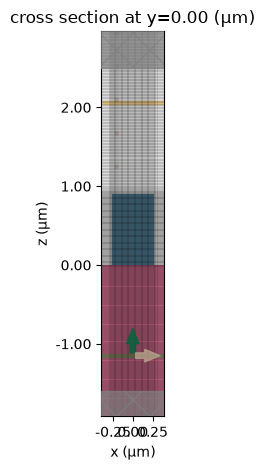

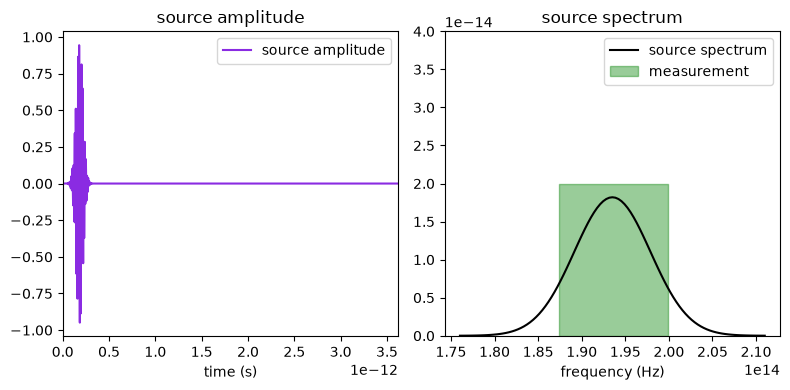

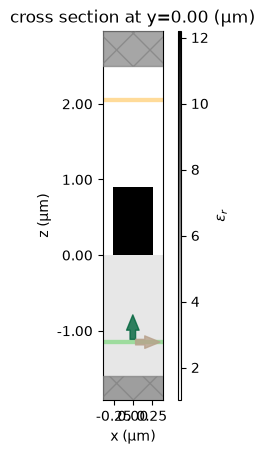

22:03:52 CEST Loading simulation from local cache. View cached task using web UI
              at                                                                
              ]8;id=10318921;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4fa8d564-5479-498c-833c-f050cc0fb3ca\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=10318922;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4fa8d564-5479-498c-833c-f050cc0fb3ca\taskId]8;;\]8;id=10318921;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4fa8d564-5479-498c-833c-f050cc0fb3ca\=]8;;\]8;id=10318923;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4fa8d564-5479-498c-833c-f050cc0fb3ca\fdve]8;;\]8;id=10318921;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4fa8d564-5479-498c-833c-f050cc0fb3ca\-4fa8d564-54]8;;\
              ]8;id=10318921;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4fa8d564-5479-498c-833c-f050cc0fb3ca\79-498c-833c-f050cc0fb3ca']8;;\.

22:03:54 CEST Estimated FlexCredit cost: 0.064. Minimum cost depends on task    
              execution details. Use 'web.real_cost(task_id)' to get the billed 
              FlexCredit cost after a simulation run.

In [11]:
#TEST 
#check the simulation domain
sim = make_unit_cell_sim(h=max_h, D=max_D, P=max_P)
ax = sim.plot(y=0)
sim.plot_grid(y=0,ax=ax)
#ax.set_aspect(0.4)
plt.show()

# Check probe and source
f, (ax1, ax2) = plt.subplots(1, 2, tight_layout=True, figsize=(8, 4))
ax1 = sim.sources[0].source_time.plot(times=np.linspace(0, sim.run_time, 1001), ax=ax1)
ax1.set_xlim(0, sim.run_time)
ax1.legend(("source amplitude",))
ax2 = sim.sources[0].source_time.plot_spectrum(
    times=np.linspace(0, sim.run_time, 1001), val="abs", ax=ax2
)
fill_max = 2e-14  # 10e-16
ymax = 4e-14  # 20e-16
ax2.fill_between(
    (f_min, f_max), [-0e-16, -0e-16], [fill_max, fill_max], alpha=0.4, color="g"
)
ax2.legend(("source spectrum", "measurement"))
ax2.set_ylim(-1e-16, ymax)
plt.show()

#check materials
fig, ax = plt.subplots()
sim.plot_eps(y=0, freq=freq_0, ax=ax)
plt.show()

job = web.Job(simulation=sim, task_name="uc_estimate")
estimated_cost = web.estimate_cost(job.task_id)

In [12]:
import tidy3d.plugins.design as tdd

#h_list = np.linspace(min_h, max_h, 4)
h_list = np.array([0.6,0.65,0.7,0.8,0.9])
D_list = np.linspace(min_D, max_D, 20)
#P_list = np.linspace(min_P, max_P, 3)
P_list = np.array([0.6,0.65,0.7,0.8])

h_param = tdd.ParameterFloat(name = 'h', span=(min_h, max_h), values = h_list)
D_param = tdd.ParameterFloat(name = 'D', span=(min_D, max_D), values = D_list)
P_param = tdd.ParameterFloat(name = 'P', span=(min_P, max_P), values = P_list)

method = tdd.MethodGrid()

design_space = tdd.DesignSpace(
    parameters = [h_param, D_param, P_param],
    method = method,
    task_name = "unit_cell_sweep",
    path_dir="./data"
)

In [13]:
def measure_transmission(sim_data):
    '''
    Returns the transmittance monitor data from the given simulation at the "p" polarization.
    The amplitude of the zero x,y-orders are returned in xArray format
    Args:
        sim_data: The simulation data containing the transmittance monitor.

    Returns:
        The xarray of complex amplitudes at every monitor frequency.
    '''
    monitor_data = sim_data['transmission_monitor'].amps.sel(polarization="p", orders_x=0, orders_y=0)
    monitor_frequencies = monitor_data.f.values
    monitor_amplitudes = monitor_data.values
    #return a list of dictionaries. Each dictionary has two key-value pairs: 'lda', the wavelength, and 'amplitude', the corresponding complex amplitude
    monitor_dict = [
        {'lda': td.C_0/f, 'amplitude': a}
        for f, a in zip(monitor_frequencies, monitor_amplitudes)
    ]
    
    return monitor_dict

In [14]:
#results = design_space.run(fn = make_unit_cell_sim, fn_post = measure_transmission)

In [15]:
#results_df = results.to_dataframe()
#save the results dataframe to file
#results_df.to_csv("results_df.csv", index=False)

In [16]:
import pandas as pd
# Load dataframe
df = pd.read_csv('results_df.csv')

# 1. Identify all 'output_' columns
output_cols = [col for col in df.columns if col.startswith('output_')]

# 2. Melt the wide columns into a single long column
melted_df = df.melt(
    id_vars=['h', 'D', 'P'], 
    value_vars=output_cols, 
    value_name='output_str'
).drop(columns=['variable']) # Drop the temporary 'variable' column (output_0, output_1, etc.)

# 3. Parse the dictionary strings safely using numpy in the evaluation namespace
def parse_dict(val):
    if pd.isna(val):
        return np.nan, np.nan
    # Evaluates strings like "{'lda': np.float64(1.5), 'amplitude': np.complex128(...)}"
    d = eval(val, {"__builtins__": {}}, {"np": np})
    return d['lda'], d['amplitude']

# Apply the parser and split into separate 'lda' and 'amplitude' columns
parsed_data = melted_df['output_str'].apply(parse_dict)
melted_df['lda'] = [item[0] for item in parsed_data]
melted_df['amplitude'] = [item[1] for item in parsed_data]

# 4. Final clean DataFrame
clean_df = melted_df.drop(columns=['output_str'])

#Save dataframe
clean_df.to_csv("tidy_results_df.csv", index=False)
clean_df

,h,D,P,lda,amplitude
0,0.60,0.12,0.60,1.5,-0.982555+0.051882j
1,0.60,0.12,0.65,1.5,-0.981778+0.064743j
2,0.60,0.12,0.70,1.5,-0.980939+0.075633j
3,0.60,0.12,0.80,1.5,-0.978886+0.089791j
4,0.65,0.12,0.60,1.5,-0.981885+0.046526j
...,...,...,...,...,...
1995,0.80,0.53,0.80,1.6,0.255692+0.180742j
1996,0.90,0.53,0.60,1.6,-0.616147+0.706094j
1997,0.90,0.53,0.65,1.6,-0.539640+0.792115j
1998,0.90,0.53,0.70,1.6,-0.503026+0.830885j


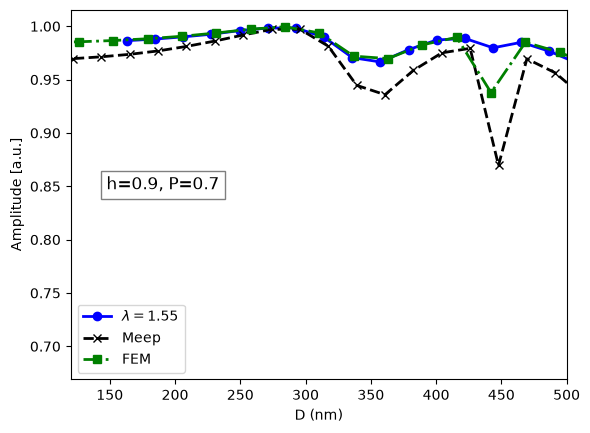

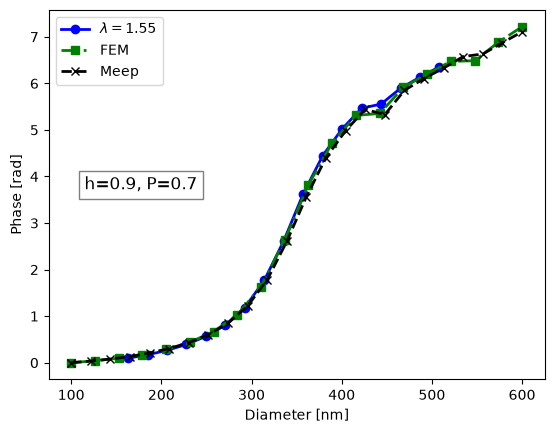

In [31]:
selected_h = h_list[4] 
selected_P = P_list[2]  

filtered_df = clean_df[
    (clean_df['h'] == selected_h) &
    (clean_df['P'] == selected_P)
]

#colormesh for amplitude as a function of D and lda
pivot_df = filtered_df.pivot_table(
    index='D', 
    columns='lda', 
    values='amplitude', 
)

D_values = pivot_df.index.values
lda_values = pivot_df.columns.values
amplitude_values = np.abs(pivot_df.values)

#phase
pivot_df_phase = filtered_df.pivot_table(
    index='D', 
    columns='lda', 
    values='amplitude', 
)

D_values = pivot_df_phase.index.values
lda_values = pivot_df_phase.columns.values
phase_values = np.unwrap(np.angle(pivot_df_phase.values),axis=0)  # Use angle for complex phases
#the phase reference
zero_phase_index = 2
phase_values -= phase_values[zero_phase_index, :]

line_colors = ['r','g','b','c','m']
fig, ax = plt.subplots()
for i, lda in enumerate(lda_values):
    if not np.isclose(lda, 1.55):
        continue
    filtered_df_lda = filtered_df[filtered_df['lda'] == lda]
    ax.plot(filtered_df_lda['D'][zero_phase_index:-1]*1e3, np.abs(filtered_df_lda['amplitude'])[zero_phase_index:-1], marker='o', color=line_colors[i % len(line_colors)], label=fr'$\lambda={np.round(lda,2)}$', linewidth=2)
ax.set_xlabel('D (nm)')
ax.set_ylabel('Amplitude [a.u.]')
#ax.set_ylim(0, 1)
ax.text(0.30, 0.55, f'h={selected_h}, P={selected_P}', transform=ax.transAxes,
        verticalalignment='top', horizontalalignment='right', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
#ax.set_title(f'Amplitude vs D for h={selected_h}, P={selected_P}')
#for comparison load previous results 
meep_phase_results_filename = "../meep/prev/unit_cell_center_1550_h900nm_res50_wvl_mode_phase.npy"
meep_phase_results = np.load(meep_phase_results_filename)
meep_tran_results_filename = "../meep/prev/unit_cell_center_1550_h900nm_res50_wvl_mode_tran.npy"
meep_tran_results = np.load(meep_tran_results_filename)
meep_diameters_filename = "../meep/prev/unit_cell_center_1550_h900nm_res50_wvl_diameters.npy"
meep_diameters = np.load(meep_diameters_filename)
#FEM data
ref_results = np.loadtxt("../meep/prev/results_S21_p700nm_h900nm.txt", skiprows=5,dtype=complex)
fem_diameters = 2*np.real(ref_results[:,1])
S21_ref = ref_results[:,3]
fem_magnitude = np.abs(S21_ref)
fem_phase = np.abs(np.unwrap(np.angle(S21_ref) - np.angle(S21_ref[0]), period=2*np.pi))

ax.plot(meep_diameters*1e3, meep_tran_results, marker='x', color='k', linestyle='--', label='Meep', linewidth=2)
ax.plot(fem_diameters, fem_magnitude, marker='s', color='g', linestyle='-.', label='FEM', linewidth=2)
ax.set_xlim(120,500)
ax.legend(loc='lower left')
plt.show()
plt.close()

fig, ax = plt.subplots()
for i, lda in enumerate(lda_values):
    if not np.isclose(lda, 1.55):
        continue
    filtered_df_lda = filtered_df[filtered_df['lda'] == lda]
    phase_values = np.angle(filtered_df_lda['amplitude'])
    phase_values -= phase_values[0]  # Reference phase to the smallest diameter for each wavelength
    phase_values = (phase_values + 2*np.pi) % (2*np.pi)
    ax.plot(filtered_df_lda['D'][zero_phase_index:-1]*1e3, np.unwrap(phase_values[zero_phase_index:-1]), 
            marker='o', color=line_colors[i % len(line_colors)], 
            label=fr'$\lambda={np.round(lda,2)}$', linewidth=2)
    ax.plot(fem_diameters, np.unwrap(fem_phase), marker='s', color='g', linestyle='-.', label='FEM', linewidth=2)
    ax.plot(meep_diameters*1e3, np.unwrap(meep_phase_results-meep_phase_results[0]), marker='x', color='k', linestyle='--', label='Meep', linewidth=2)
ax.set_xlabel('Diameter [nm]')
ax.set_ylabel('Phase [rad]')
ax.text(0.30, 0.55, f'h={selected_h}, P={selected_P}', transform=ax.transAxes,
        verticalalignment='top', horizontalalignment='right', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
#ax.set_title(f'Phase vs D for h={selected_h}, P={selected_P}')

ax.legend()
plt.show()
plt.close()


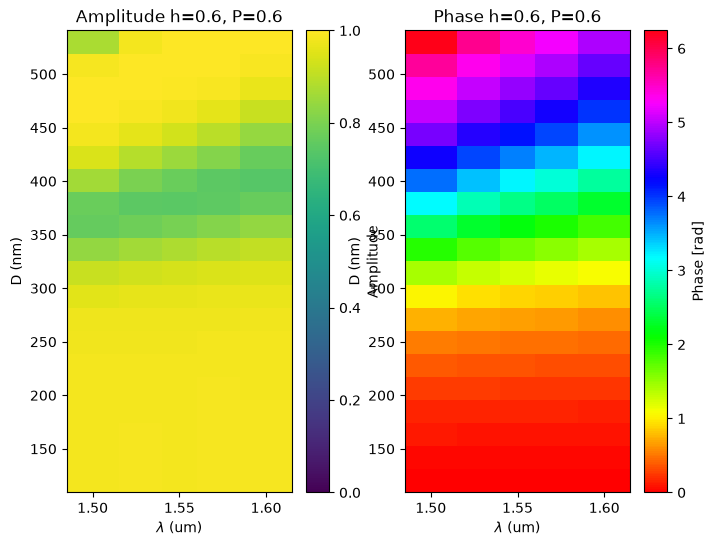

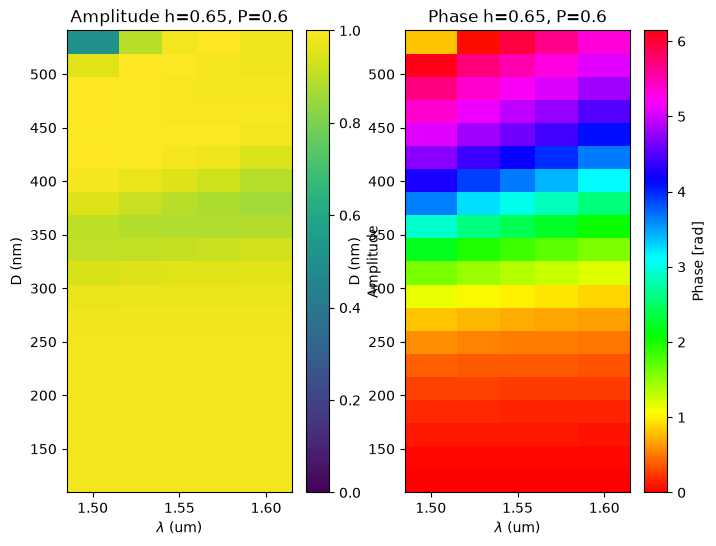

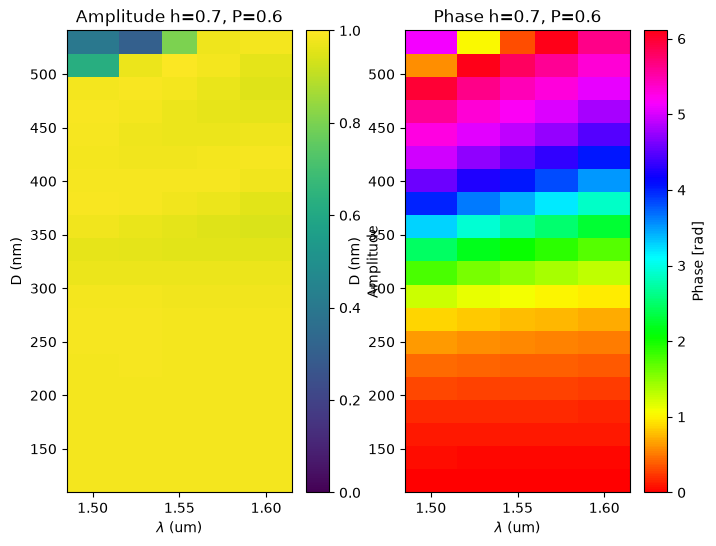

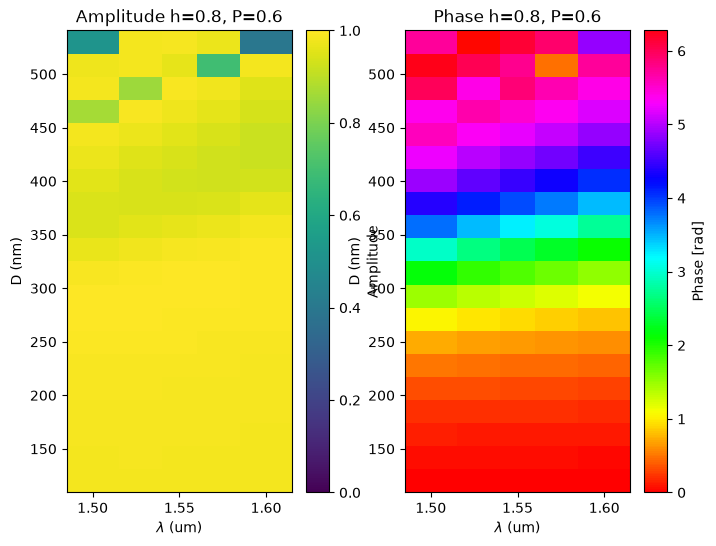

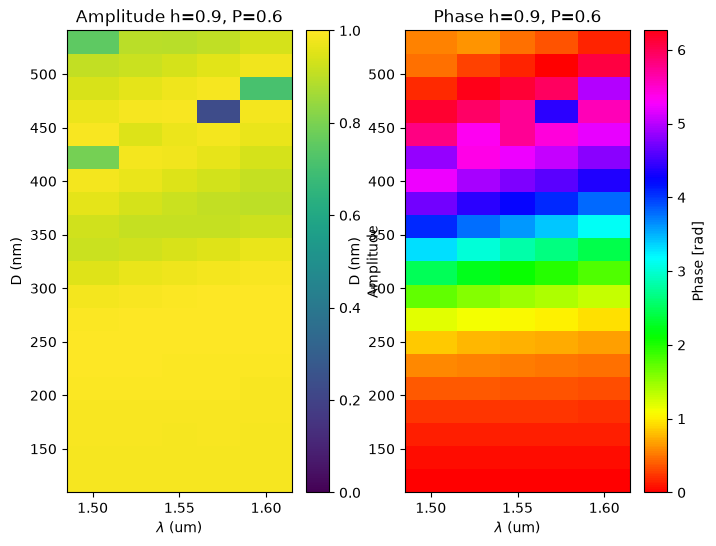

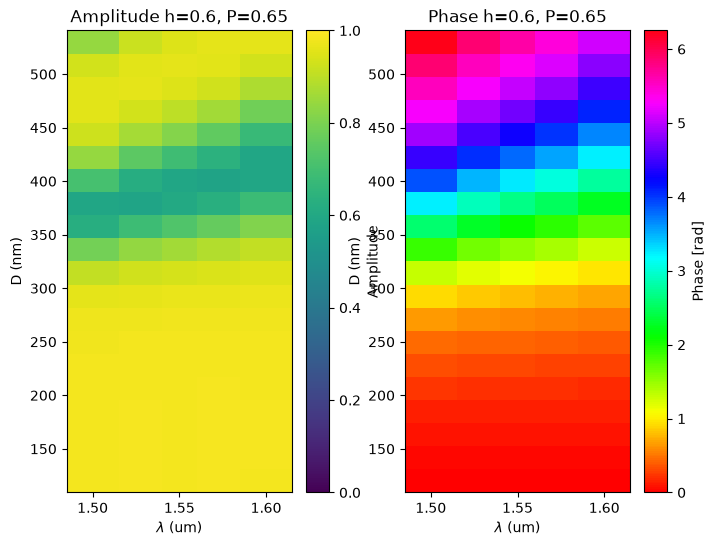

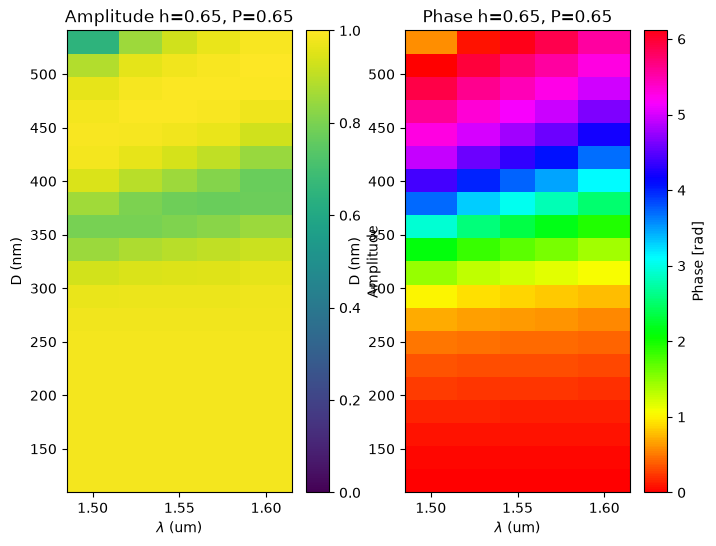

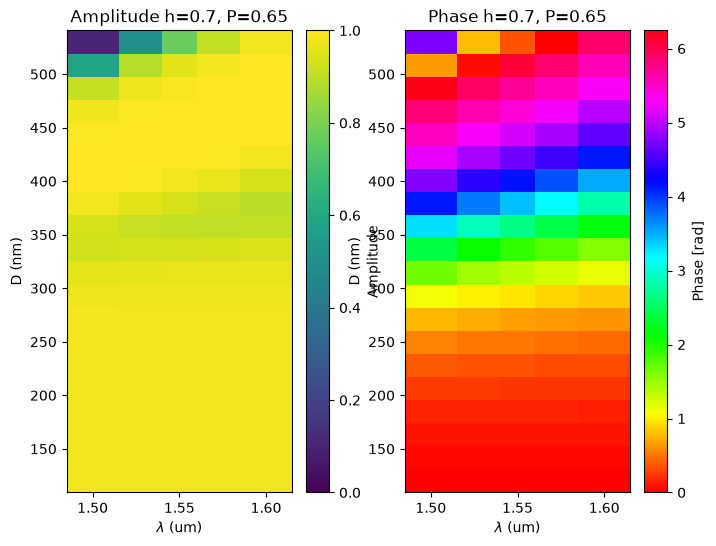

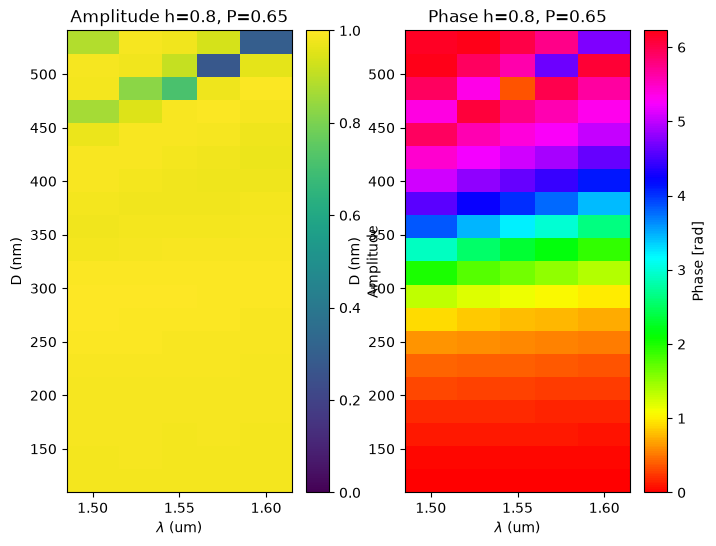

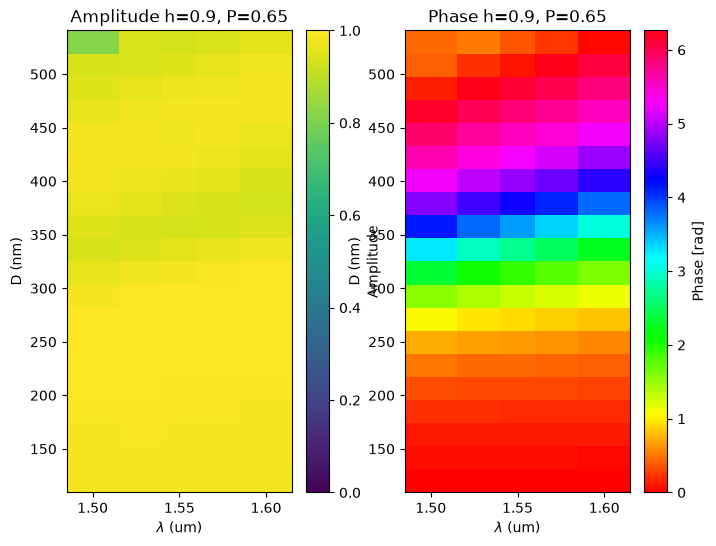

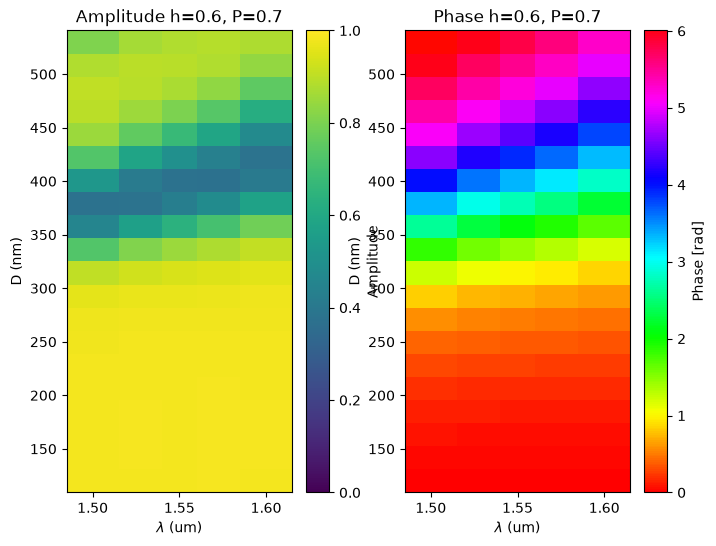

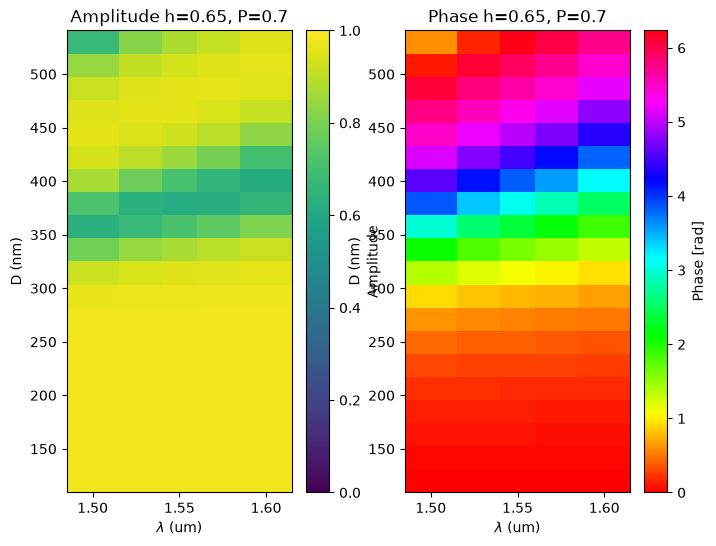

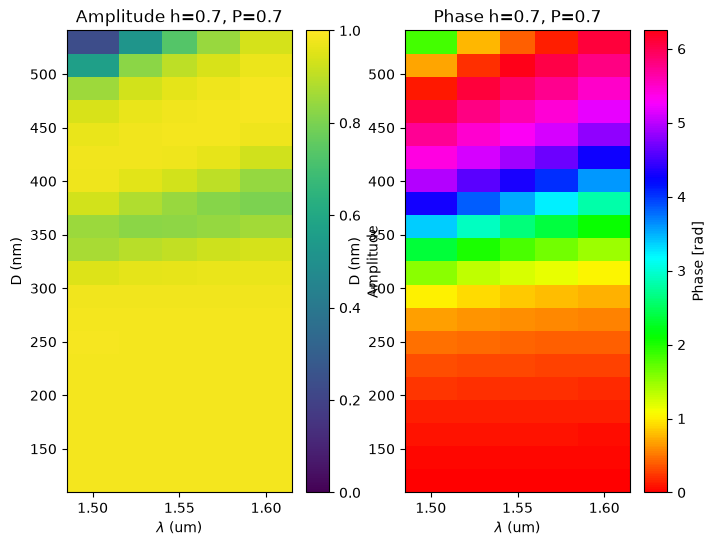

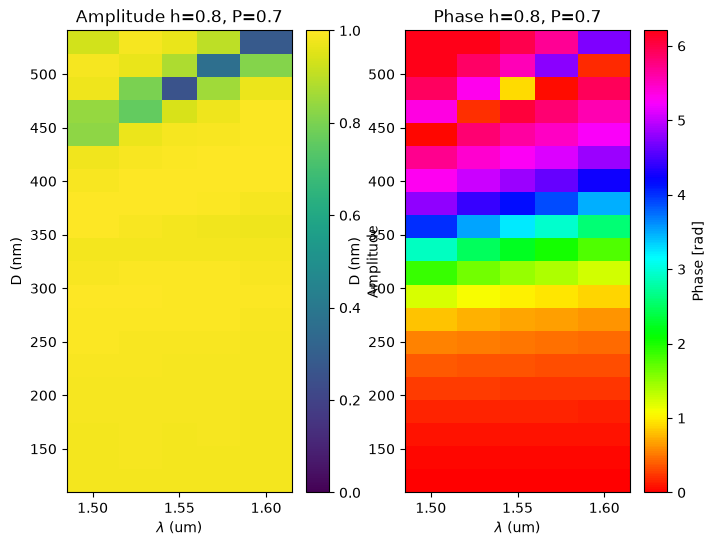

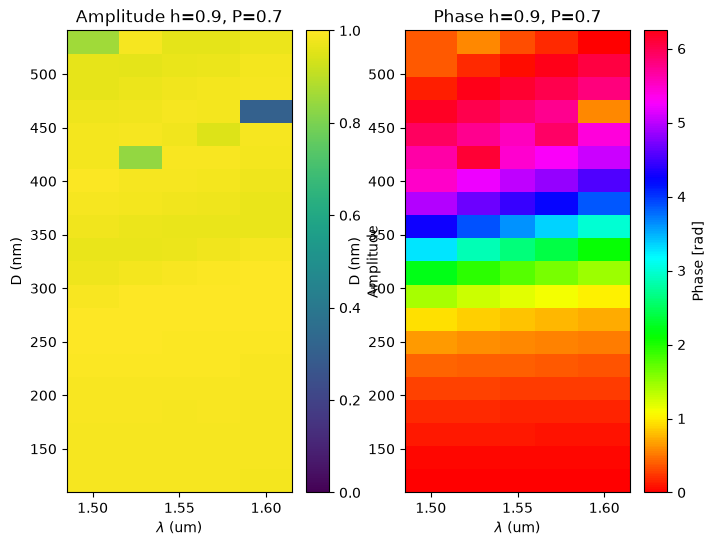

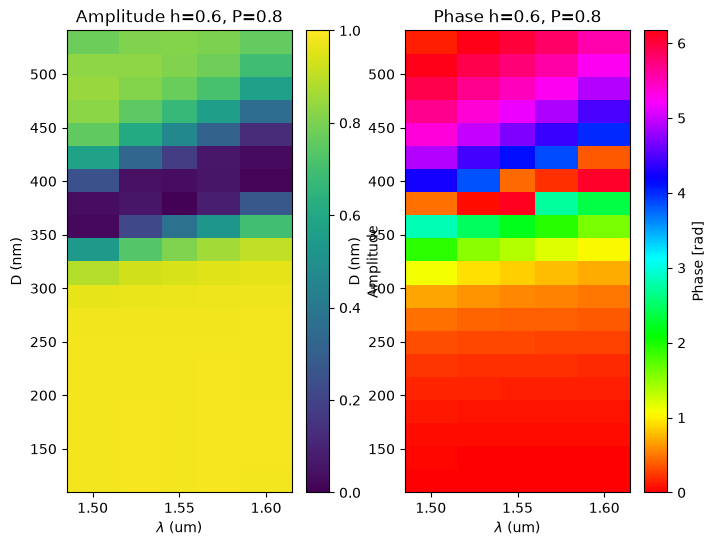

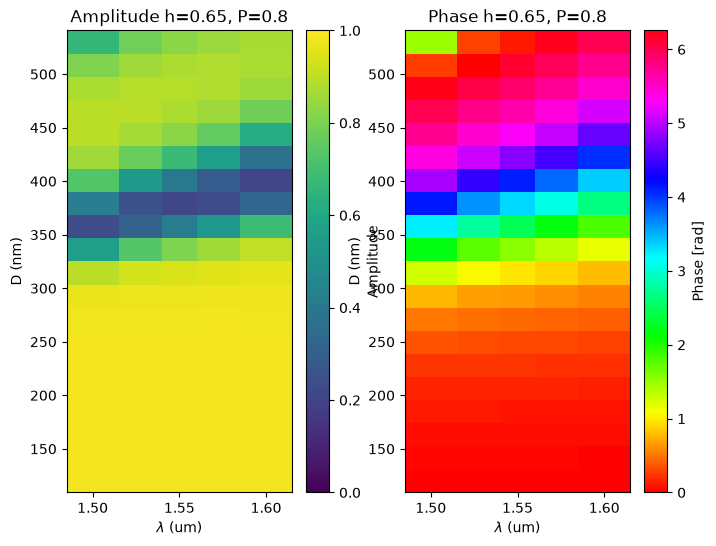

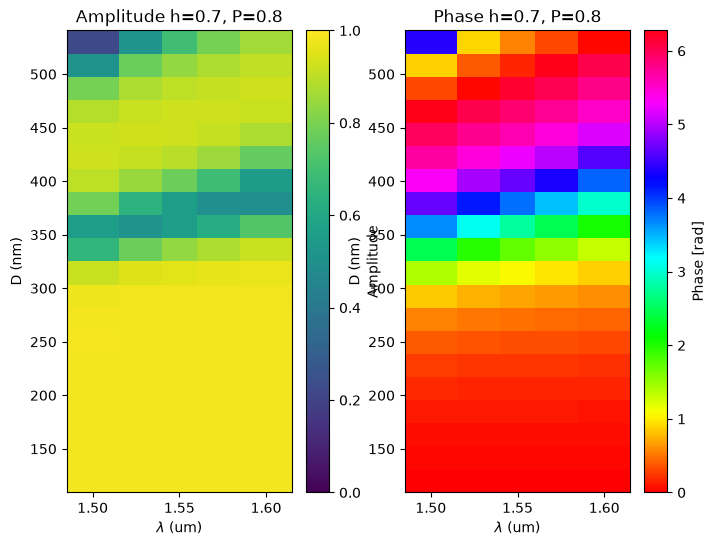

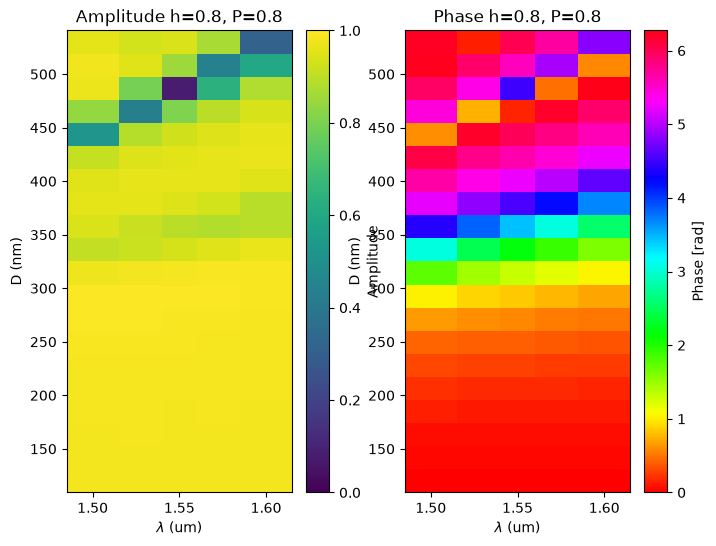

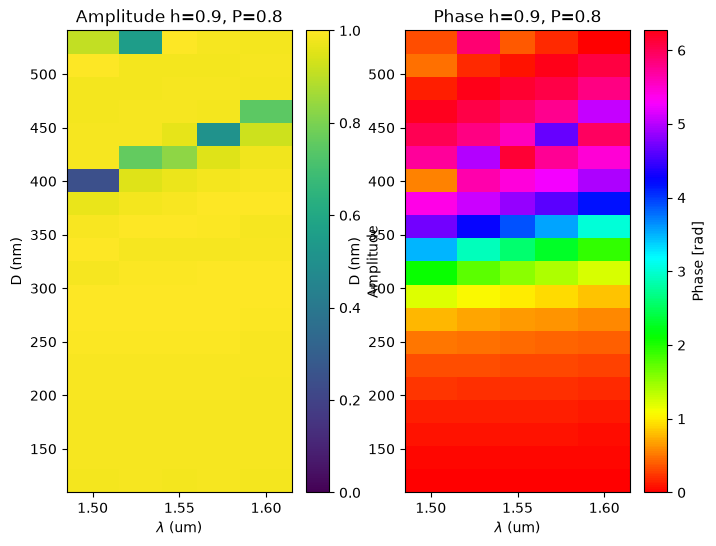

In [18]:
for selected_P in P_list:    
    for selected_h in h_list:
        filtered_df = clean_df[
            (clean_df['h'] == selected_h) &
            (clean_df['P'] == selected_P)
        ]

        #plot the colormesh for amplitude as a function of D and lda
        pivot_df = filtered_df.pivot_table(
            index='D', 
            columns='lda', 
            values='amplitude', 
        )

        D_values = pivot_df.index.values
        lda_values = pivot_df.columns.values
        amplitude_values = np.abs(pivot_df.values)
        phase_values = np.angle(pivot_df.values)
        phase_values -= phase_values[0, :]  # Reference phase to the smallest diameter for each wavelength
        phase_values = (phase_values + 2*np.pi) % (2*np.pi)
        fig, ax = plt.subplots(1, 2, figsize=(8, 6))
        c = ax[0].pcolormesh(lda_values, D_values*1e3, amplitude_values, shading='auto')
        ax[0].set_xlabel(r'$\lambda$ (um)')
        ax[0].set_ylabel('D (nm)')
        ax[0].set_title(f'Amplitude h={selected_h}, P={selected_P}')
        c.set_clim(0, 1)
        fig.colorbar(c, ax=ax[0], label='Amplitude')
        c1 = ax[1].pcolormesh(lda_values, D_values*1e3, phase_values, shading='auto', cmap='hsv')
        ax[1].set_xlabel(r'$\lambda$ (um)')
        ax[1].set_ylabel('D (nm)')
        ax[1].set_title(f'Phase h={selected_h}, P={selected_P}')
        fig.colorbar(c1, ax=ax[1], label='Phase [rad]')

        plt.show()
        plt.close()
